# Problema 5 — Multicolinealidad y Dimensionalidad
## Dataset: Base 2 — Matrícula y secciones 2023

**Qué vamos a aprender:**
1. Qué es la multicolinealidad y cómo detectarla con VIF
2. Cómo el R² se infla con muchas features irrelevantes
3. Por qué R² Ajustado es más honesto
4. Cómo la regularización (Ridge, Lasso) resuelve ambos problemas

### Los dos problemas conectados
- **Multicolinealidad**: features altamente correlacionadas entre sí → coeficientes inestables
- **Curse of dimensionality**: demasiadas features para pocos datos → overfitting inevitable

En el dataset de escuelas, la **matrícula total por grado** contiene columnas muy correlacionadas
entre sí (los grados consecutivos se parecen), lo que genera un escenario perfecto para ver multicolinealidad real.

## 0. Setup y carga

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

ARCHIVO = 'data/matricula_secciones_2023.csv'
df_raw = pd.read_csv(ARCHIVO, sep=';', encoding='utf-8-sig', low_memory=False)

# Columnas de matrícula por año (muy correlacionadas entre sí)
anios = ['_1','_2','_3','_4','_5','_6','_7','_8','_9','_10','_11','_12']
anios_disponibles = [c for c in anios if c in df_raw.columns]

df = df_raw[anios_disponibles].apply(pd.to_numeric, errors='coerce').copy()
df = df.dropna(how='all').fillna(0)
df = df[(df.sum(axis=1) > 0)].copy()

# Target: cantidad total de secciones de la escuela.
# Depende de la matrícula de cada año pero NO es una suma exacta de las features
# (si usáramos la matrícula total, el modelo la reconstruiría perfecto con R²=1
# y no se vería ningún efecto de la multicolinealidad).
sec_cols = [c for c in ['_sec1','_sec2','_sec3','_sec4','_sec5','_sec6','_sec7','_sec8','_sec9','_sec10','_sec11','_sec12'] if c in df_raw.columns]
df['secciones_total'] = df_raw.loc[df.index, sec_cols].apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1)
df = df[df['secciones_total'] > 0].copy()
print(f'Escuelas: {len(df):,}')
print(f'Columnas por año disponibles: {anios_disponibles}')

Escuelas: 27,223
Columnas por año disponibles: ['_1', '_2', '_3', '_4', '_5', '_6', '_7', '_8', '_9', '_10', '_11', '_12']


## 1. Evidencia de multicolinealidad — mapa de correlaciones

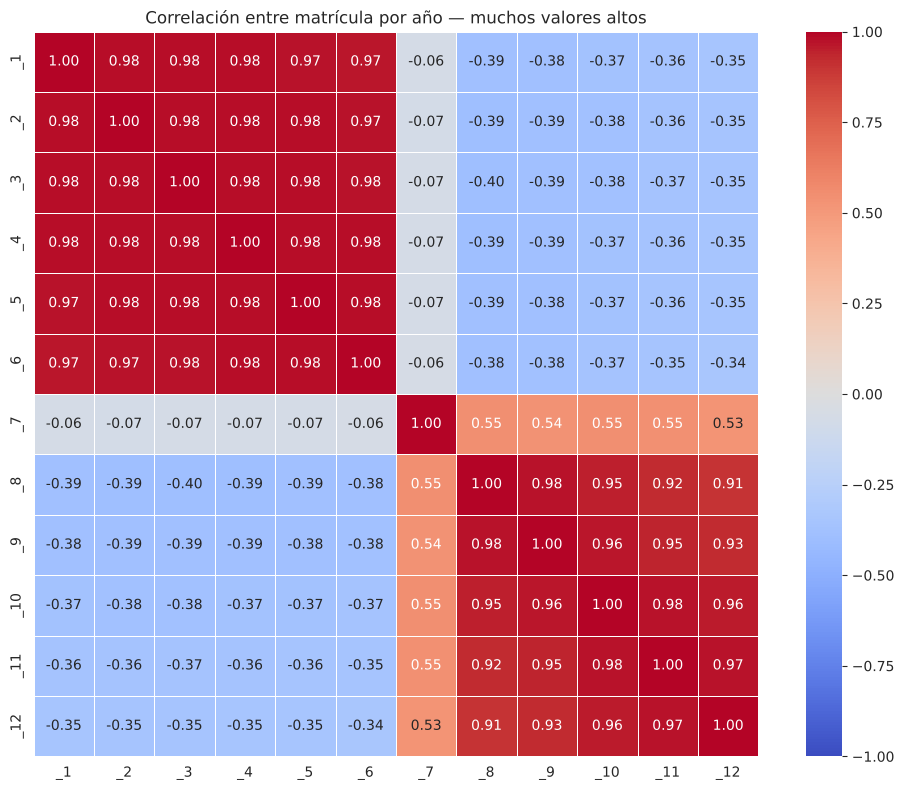

Pares con correlación > 0.85 (multicolinealidad potencial):
  _1 y _2: r = 0.980
  _1 y _3: r = 0.977
  _1 y _4: r = 0.977
  _1 y _5: r = 0.972
  _1 y _6: r = 0.967
  _2 y _3: r = 0.982
  _2 y _4: r = 0.981
  _2 y _5: r = 0.978
  _2 y _6: r = 0.973
  _3 y _4: r = 0.982
  _3 y _5: r = 0.980
  _3 y _6: r = 0.976
  _4 y _5: r = 0.981
  _4 y _6: r = 0.978
  _5 y _6: r = 0.979
  _8 y _9: r = 0.975
  _8 y _10: r = 0.946
  _8 y _11: r = 0.925
  _8 y _12: r = 0.905
  _9 y _10: r = 0.963
  _9 y _11: r = 0.945
  _9 y _12: r = 0.928
  _10 y _11: r = 0.977
  _10 y _12: r = 0.958
  _11 y _12: r = 0.975


In [2]:
corr = df[anios_disponibles].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlación entre matrícula por año — muchos valores altos')
plt.tight_layout()
plt.show()

# Identificar pares altamente correlacionados
print('Pares con correlación > 0.85 (multicolinealidad potencial):')
n = len(corr)
for i in range(n):
    for j in range(i+1, n):
        if abs(corr.iloc[i, j]) > 0.85:
            print(f'  {corr.columns[i]} y {corr.columns[j]}: r = {corr.iloc[i,j]:.3f}')

## 2. Variance Inflation Factor (VIF)

**Fórmula**: VIF_j = 1 / (1 - R²_j), donde R²_j es el R² de regresionar X_j sobre las otras features.

| VIF | Interpretación |
|---|---|
| 1 | Sin multicolinealidad |
| 1-5 | Multicolinealidad moderada |
| **5-10** | **Multicolinealidad considerable — investigar** |
| **> 10** | **Multicolinealidad severa — acción requerida** |

Variance Inflation Factor (VIF) por variable:
_4     46.47
_3     44.36
_2     42.84
_5     41.38
_11    35.66
_6     33.88
_1     31.50
_10    30.33
_9     27.50
_8     20.95
_12    19.22
_7      1.51

VIF máximo: 46.47
Variables con VIF > 10: 11
Variables con VIF > 5:  11


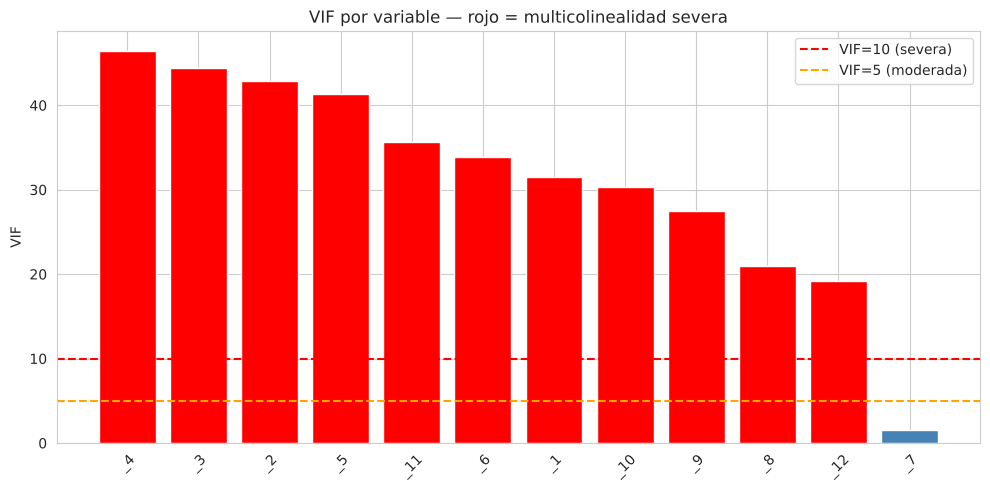

In [3]:
def calcular_vif(X):
    """Calcula VIF para cada columna regressando sobre las demás."""
    vifs = {}
    for i, col in enumerate(X.columns):
        y_col = X[col].values
        X_others = X.drop(columns=[col]).values
        lr = LinearRegression().fit(X_others, y_col)
        r2 = lr.score(X_others, y_col)
        vifs[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vifs).sort_values(ascending=False)

# Tomar una muestra para velocidad
muestra = df.sample(n=min(5000, len(df)), random_state=42)
vif_series = calcular_vif(muestra[anios_disponibles])

print('Variance Inflation Factor (VIF) por variable:')
print(vif_series.round(2).to_string())
print()
print(f'VIF máximo: {vif_series.max():.2f}')
print(f'Variables con VIF > 10: {(vif_series > 10).sum()}')
print(f'Variables con VIF > 5:  {(vif_series > 5).sum()}')

# Visualización
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['red' if v > 10 else 'orange' if v > 5 else 'steelblue' for v in vif_series.values]
bars = ax.bar(vif_series.index, vif_series.values, color=colors, edgecolor='white')
ax.axhline(10, color='red', linestyle='--', label='VIF=10 (severa)')
ax.axhline(5, color='orange', linestyle='--', label='VIF=5 (moderada)')
ax.set_title('VIF por variable — rojo = multicolinealidad severa')
ax.set_ylabel('VIF')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. El efecto en los coeficientes — ¿qué tan inestables son?

La multicolinealidad **no afecta el R² del modelo**, pero **desestabiliza los coeficientes individuales**.
Cualquier cambio pequeño en los datos puede cambiar drásticamente los coeficientes.

Desvío estándar de coeficientes en 30 submuestras — modelo SIN regularización:
_1     0.901
_2     0.967
_3     1.313
_4     1.085
_5     1.044
_6     0.822
_7     0.259
_8     1.234
_9     1.262
_10    1.120
_11    1.497
_12    1.217

Desvío estándar de coeficientes — con Ridge (α=100):
_1     0.105
_2     0.093
_3     0.121
_4     0.090
_5     0.100
_6     0.101
_7     0.191
_8     0.219
_9     0.132
_10    0.108
_11    0.196
_12    0.201


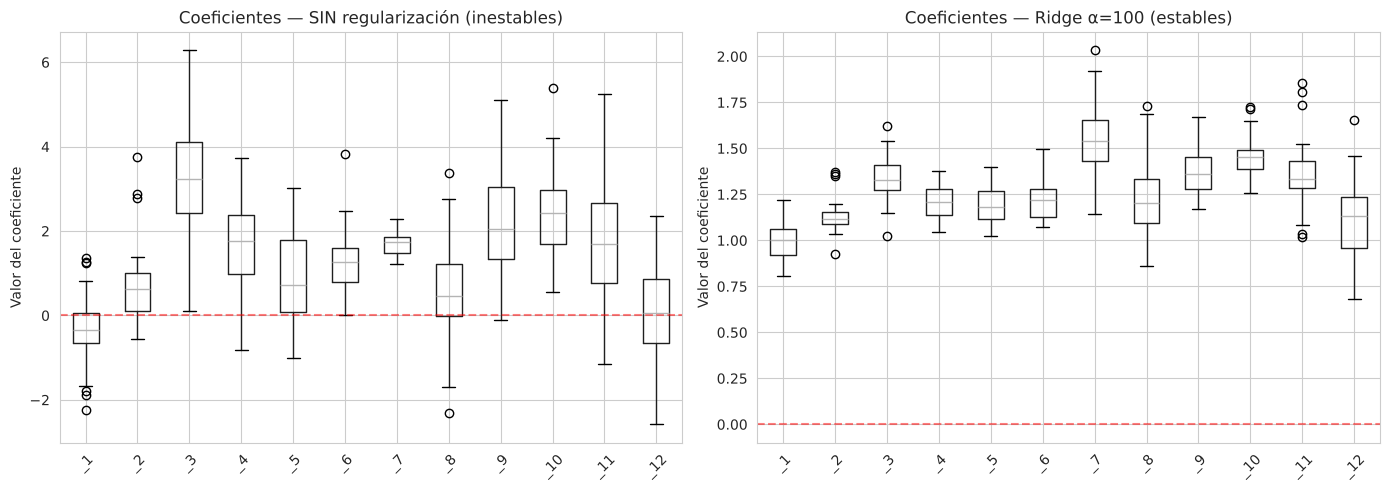


Desvío promedio de los coeficientes: 1.060 sin regularización vs 0.138 con Ridge.
Sin regularización, el 13% de los coeficientes cambia de signo según la submuestra: no se pueden interpretar.
Observación: los boxes mucho más angostos con Ridge muestran la estabilización de coeficientes.


In [4]:
# Experimento: entrenar el mismo modelo sobre 30 submuestras bootstrap y ver la variabilidad
y = df['secciones_total'].values
# Escalamos para que los coeficientes sean comparables y la penalización de Ridge tenga efecto
X_multi = StandardScaler().fit_transform(df[anios_disponibles].values)

# Sin regularización
coeficientes_lin = []
for seed in range(30):
    idx = np.random.RandomState(seed).choice(len(df), size=500, replace=True)
    lr = LinearRegression().fit(X_multi[idx], y[idx])
    coeficientes_lin.append(lr.coef_)

coefs_lin = pd.DataFrame(coeficientes_lin, columns=anios_disponibles)
print('Desvío estándar de coeficientes en 30 submuestras — modelo SIN regularización:')
print(coefs_lin.std().round(3).to_string())

# Con Ridge
coeficientes_ridge = []
for seed in range(30):
    idx = np.random.RandomState(seed).choice(len(df), size=500, replace=True)
    rr = Ridge(alpha=100.0).fit(X_multi[idx], y[idx])
    coeficientes_ridge.append(rr.coef_)

coefs_ridge = pd.DataFrame(coeficientes_ridge, columns=anios_disponibles)
print('\nDesvío estándar de coeficientes — con Ridge (α=100):')
print(coefs_ridge.std().round(3).to_string())

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

coefs_lin.boxplot(ax=axes[0], rot=45)
axes[0].set_title('Coeficientes — SIN regularización (inestables)')
axes[0].set_ylabel('Valor del coeficiente')
axes[0].axhline(0, color='red', linestyle='--', alpha=0.5)

coefs_ridge.boxplot(ax=axes[1], rot=45)
axes[1].set_title('Coeficientes — Ridge α=100 (estables)')
axes[1].set_ylabel('Valor del coeficiente')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
signos = (np.sign(coefs_lin) != np.sign(coefs_lin.mean())).values.mean()
print(f'\nDesvío promedio de los coeficientes: {coefs_lin.std().mean():.3f} sin regularización vs {coefs_ridge.std().mean():.3f} con Ridge.')
print(f'Sin regularización, el {signos:.0%} de los coeficientes cambia de signo según la submuestra: no se pueden interpretar.')
print('Observación: los boxes mucho más angostos con Ridge muestran la estabilización de coeficientes.')

## 4. El R² inflado por features irrelevantes

Agregamos **features aleatorias** (ruido puro, sin información sobre el target) y vemos cómo R² sube
falsamente mientras R² Ajustado se mantiene honesto.

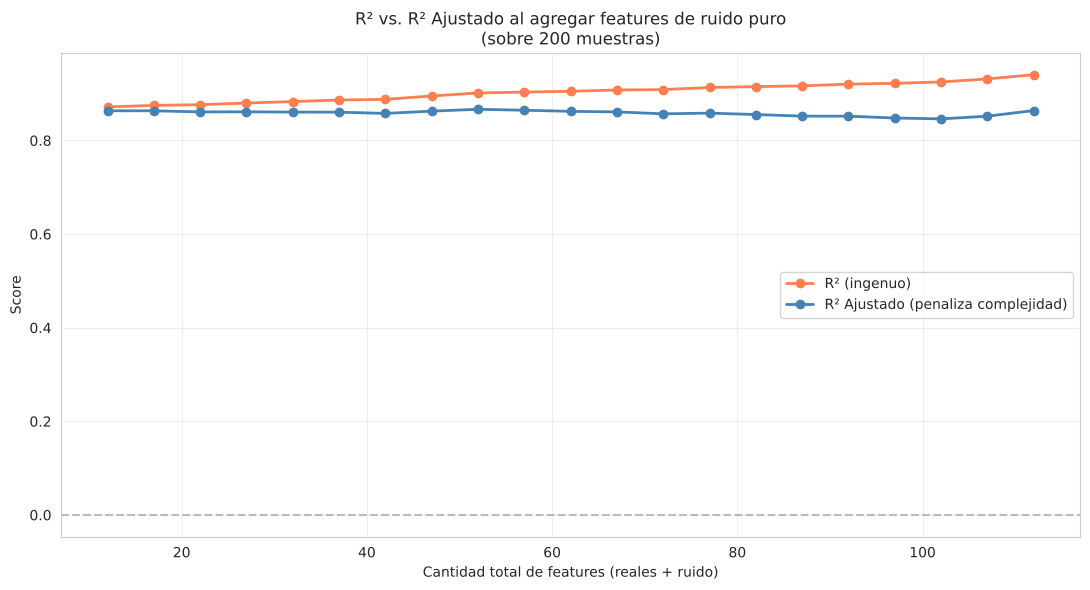


🔍 Observación clave:
  Con 12 features reales: R²=0.872, Adj R²=0.863
  Con 112 features (ruido incluido): R²=0.941, Adj R²=0.864
  R² subió a 0.941 (parece mejor modelo) — pero es ILUSORIO.
  R² Ajustado delata que el "mejor" modelo es el más simple.


In [5]:
def r2_ajustado(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

# Usar una muestra PEQUEÑA para que el efecto del curse sea visible
muestra = df.sample(n=200, random_state=42)
y_s = muestra['secciones_total'].values
X_base = muestra[anios_disponibles].values

# Agregar progresivamente features aleatorias sin señal
np.random.seed(42)
n_extras_max = 100
X_extras = np.random.randn(len(muestra), n_extras_max)

n = len(muestra)
r2_list = []
adj_r2_list = []
n_features_list = []

for k in range(0, n_extras_max + 1, 5):
    X_k = np.hstack([X_base, X_extras[:, :k]])
    p = X_k.shape[1]
    lr = LinearRegression().fit(X_k, y_s)
    r2 = lr.score(X_k, y_s)
    adj = r2_ajustado(r2, n, p)
    r2_list.append(r2)
    adj_r2_list.append(adj)
    n_features_list.append(p)

# Gráfico
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(n_features_list, r2_list, 'o-', color='coral', linewidth=2, label='R² (ingenuo)')
ax.plot(n_features_list, adj_r2_list, 'o-', color='steelblue', linewidth=2, label='R² Ajustado (penaliza complejidad)')
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Cantidad total de features (reales + ruido)')
ax.set_ylabel('Score')
ax.set_title('R² vs. R² Ajustado al agregar features de ruido puro\n(sobre 200 muestras)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\n🔍 Observación clave:')
print(f'  Con {len(anios_disponibles)} features reales: R²={r2_list[0]:.3f}, Adj R²={adj_r2_list[0]:.3f}')
print(f'  Con {n_features_list[-1]} features (ruido incluido): R²={r2_list[-1]:.3f}, Adj R²={adj_r2_list[-1]:.3f}')
print(f'  R² subió a {r2_list[-1]:.3f} (parece mejor modelo) — pero es ILUSORIO.')
print(f'  R² Ajustado delata que el "mejor" modelo es el más simple.')

## 5. Curse of dimensionality — el overfitting es inevitable

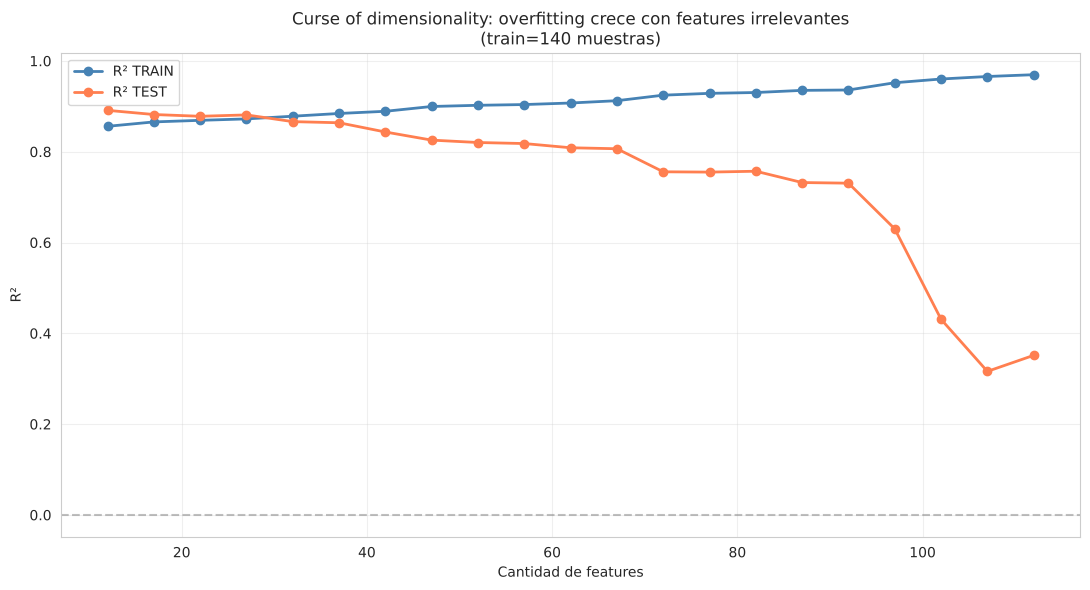

Escenario: 140 muestras de training, 60 de test.
Al agregar features sin señal: el R² de train sigue subiendo (memoriza ruido),
mientras el R² de test colapsa (el modelo no generaliza).

Ejemplo extremo con 112 features y 140 muestras:
  R² train: 0.970  ← modelo "perfecto" en train
  R² test:  0.351  ← modelo catastrófico en test


In [6]:
# Split y comparar train vs test para cada cantidad de features
X_base_200 = muestra[anios_disponibles].values
y_200 = muestra['secciones_total'].values

X_train_base, X_test_base, y_train_200, y_test_200 = train_test_split(
    X_base_200, y_200, test_size=0.3, random_state=42
)
X_train_extras = np.random.RandomState(43).randn(len(X_train_base), n_extras_max)
X_test_extras  = np.random.RandomState(44).randn(len(X_test_base), n_extras_max)

train_r2_list = []
test_r2_list  = []
n_list        = []

for k in range(0, n_extras_max + 1, 5):
    X_tr = np.hstack([X_train_base, X_train_extras[:, :k]])
    X_te = np.hstack([X_test_base, X_test_extras[:, :k]])
    lr = LinearRegression().fit(X_tr, y_train_200)
    train_r2_list.append(lr.score(X_tr, y_train_200))
    test_r2_list.append(lr.score(X_te, y_test_200))
    n_list.append(X_tr.shape[1])

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(n_list, train_r2_list, 'o-', color='steelblue', linewidth=2, label='R² TRAIN')
ax.plot(n_list, test_r2_list, 'o-', color='coral', linewidth=2, label='R² TEST')
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Cantidad de features')
ax.set_ylabel('R²')
ax.set_title('Curse of dimensionality: overfitting crece con features irrelevantes\n(train=140 muestras)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Escenario: {len(X_train_base)} muestras de training, {len(X_test_base)} de test.')
print(f'Al agregar features sin señal: el R² de train sigue subiendo (memoriza ruido),')
print(f'mientras el R² de test colapsa (el modelo no generaliza).')
print(f'\nEjemplo extremo con {n_list[-1]} features y {len(X_train_base)} muestras:')
print(f'  R² train: {train_r2_list[-1]:.3f}  ← modelo "perfecto" en train')
print(f'  R² test:  {test_r2_list[-1]:.3f}  ← modelo catastrófico en test')

## 6. La solución — regularización

### Ridge (L2): penaliza coeficientes al cuadrado
- Shrinka todos los coeficientes hacia 0
- No elimina features — las reduce
- Mejor con multicolinealidad severa

### Lasso (L1): penaliza valor absoluto
- Pone coeficientes en exactamente 0
- Hace selección automática de features
- Útil cuando hay muchas features irrelevantes

In [7]:
# Comparar Linear, Ridge, Lasso en el escenario con 100 features (mayoría ruido)
X_tr_full = np.hstack([X_train_base, X_train_extras])
X_te_full = np.hstack([X_test_base, X_test_extras])

# Escalar (necesario para regularización)
scaler = StandardScaler().fit(X_tr_full)
X_tr_sc = scaler.transform(X_tr_full)
X_te_sc = scaler.transform(X_te_full)

modelos = {
    'Linear (sin regularización)': LinearRegression(),
    'Ridge α=1':   Ridge(alpha=1.0),
    'Ridge α=100': Ridge(alpha=100.0),
    'Lasso α=1':   Lasso(alpha=1.0, max_iter=10000),
    'Lasso α=10':  Lasso(alpha=10.0, max_iter=10000),
}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_tr_sc, y_train_200)
    r2_tr = modelo.score(X_tr_sc, y_train_200)
    r2_te = modelo.score(X_te_sc, y_test_200)
    coefs_nonzero = np.sum(np.abs(modelo.coef_) > 1e-6)
    resultados.append({'Modelo': nombre, 'R² train': r2_tr, 'R² test': r2_te,
                       'Features usadas': coefs_nonzero, 'Gap': r2_tr - r2_te})

tabla = pd.DataFrame(resultados).round(4)
print(f'Escenario: {X_tr_sc.shape[0]} muestras, {X_tr_sc.shape[1]} features ({len(anios_disponibles)} reales + {n_extras_max} ruido).')
print()
print(tabla.to_string(index=False))
print()
print('🔍 Observaciones:')
print('  - Linear sin reg: R² train altísimo, R² test catastrófico → overfitting extremo.')
print('  - Ridge: reduce el gap progresivamente, todas las features usadas pero shrinkeadas.')
print('  - Lasso: elimina features ruidosas (pone coef=0), selecciona automáticamente las útiles.')

Escenario: 140 muestras, 112 features (12 reales + 100 ruido).

                     Modelo  R² train  R² test  Features usadas     Gap
Linear (sin regularización)    0.9696   0.3515              112  0.6181
                  Ridge α=1    0.9675   0.5083              112  0.4592
                Ridge α=100    0.9054   0.7601              112  0.1453
                  Lasso α=1    0.8015   0.8109                6 -0.0094
                 Lasso α=10    0.0000  -0.0550                0  0.0550

🔍 Observaciones:
  - Linear sin reg: R² train altísimo, R² test catastrófico → overfitting extremo.
  - Ridge: reduce el gap progresivamente, todas las features usadas pero shrinkeadas.
  - Lasso: elimina features ruidosas (pone coef=0), selecciona automáticamente las útiles.


In [8]:
# Ver qué features seleccionó Lasso
lasso = Lasso(alpha=1.0, max_iter=10000).fit(X_tr_sc, y_train_200)
n_reales = len(anios_disponibles)
coefs_lasso = lasso.coef_

reales_activos = np.sum(np.abs(coefs_lasso[:n_reales]) > 1e-6)
ruido_activos  = np.sum(np.abs(coefs_lasso[n_reales:]) > 1e-6)

print(f'Features reales conservadas por Lasso: {reales_activos} / {n_reales}')
print(f'Features de ruido conservadas por Lasso: {ruido_activos} / {n_extras_max}')
print()
print(f'Lasso (α=1) descartó {n_extras_max - ruido_activos} de {n_extras_max} features de ruido y se quedó con {reales_activos} de las {n_reales} reales:')
print('como las features reales son casi redundantes entre sí (VIF > 10), le alcanza con unas pocas para explicar el target.')

Features reales conservadas por Lasso: 6 / 12
Features de ruido conservadas por Lasso: 0 / 100

Lasso (α=1) descartó 100 de 100 features de ruido y se quedó con 6 de las 12 reales:
como las features reales son casi redundantes entre sí (VIF > 10), le alcanza con unas pocas para explicar el target.


## 7. Resumen — dónde están los problemas y por qué

### Multicolinealidad

**Dónde aparece:**
- En features que miden variantes de lo mismo (matrícula por año, varones/mujeres vs. total)
- En variables dummy con más categorías que necesarias
- En features derivadas (x, x², x³)

**Por qué es un problema:**
- No afecta el poder predictivo del modelo
- **Sí afecta la interpretabilidad**: los coeficientes se vuelven aleatorios
- Pequeños cambios en datos → grandes cambios en coeficientes
- Intervalos de confianza se inflan → tests estadísticos pierden poder

**Cómo detectarlo:**
1. Correlation matrix: pares con |r| > 0.85
2. **VIF > 10** (umbral estándar)
3. Coeficientes con signos inesperados

**Cómo resolverlo:**
1. Eliminar una de las features correlacionadas
2. Crear una feature compuesta (ej: total en lugar de por año)
3. Aplicar PCA para descorrelacionar
4. Usar Ridge para estabilizar coeficientes

---

### Curse of dimensionality

**Dónde aparece:**
- Cuando p (features) se acerca o supera n (muestras)
- Con features de texto (vocabulario enorme)
- Con variables dummy explosivas

**Por qué es un problema:**
- Overfitting casi inevitable
- R² sube falsamente con features irrelevantes
- Los modelos basados en distancias (KNN, K-Means) fallan

**Cómo detectarlo:**
- Ratio p/n > 1/10 es señal de alarma
- Gap grande entre R² train y R² test
- **R² mucho mayor que R² Ajustado**

**Cómo resolverlo:**
| Estrategia | Cuándo usar |
|---|---|
| Lasso | Muchas features potencialmente irrelevantes |
| Ridge | Multicolinealidad + pocas muestras |
| ElasticNet | Combinación de los dos casos |
| PCA / UMAP | Reducción de dimensionalidad general |
| Feature selection (SelectKBest, RFE) | Cuando interpretabilidad importa |

### Regla operativa
> 1. **Ratio p/n < 1/10**: ideal.
> 2. **Reportar siempre R² Ajustado**, no solo R².
> 3. **Calcular VIF** antes de interpretar coeficientes.
> 4. **Usar regularización** como default cuando p > n/5.